**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Jesus Gomez-Braña Gonzalez
*   MATRÍCULA: A01841439

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [414]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [415]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

# Ocultar advertencias (warnings) de la ejecución
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
  - 8 de tipo texto
  - 5 con decimales
  - 2 enteros
* Determina la cantidad de valores únicos por columna.

| Columna | Valores Únicos |
| :--- | :---: |
| **age** | 50 |
| **sex** | 2 |
| **origin** | 4 |
| **cp** | 4 |
| **trestbps** | 60 |
| **chol** | 216 |
| **fbs** | 2 |
| **restecg** | 3 |
| **thalch** | 119 |
| **exang** | 2 |
| **oldpeak** | 53 |
| **slope** | 3 |
| **ca** | 4 |
| **thal** | 3 |
| **num** | 5 |

In [416]:
cardio_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Ciencia de datos/Actividad5/heart_disease.csv',index_col='id')
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


In [417]:
cardio_df.dtypes.value_counts()

,count
object,8
float64,5
int64,2


In [418]:
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.
---
Si existen variables categoricas dentro de la muestra codificada como numeros, las cuales son ca: Nùmero de vasos principales coloreados por fluoroscopía. Este siendo un dato ordinal ya que es una cantidad done un numero es mayor que el otro, representa una diferencia medible y no abstracta. Num tambien es otra variable categorica lo cual indica el grado de la enfermedad donde 0 es sano y 1-4 es enfermo. Esta de hecho es la variable de salida o etiqueta (Lo que buscamos predecir). Esta tambien es una variable ordinal ya que aunque arbitraria, usa una escala para indicar niveles de serveridad.

In [419]:
cardio_df.select_dtypes(include=[np.number]).nunique()

,0
age,50
trestbps,60
chol,216
thalch,119
oldpeak,53
ca,4
num,5


In [420]:
cardio_df.ca.unique()

array([ 0.,  3.,  2.,  1., nan])

In [421]:
cardio_df.num.unique()

array([0, 2, 1, 3, 4])

In [422]:
# Este bloque fue generado por Gemini 3.5 flash
from pandas.api.types import CategoricalDtype

# Definimos el orden lógico de las categorías para cada variable ordinal
# Para 'ca', el orden natural es de 0 a 3 (excluyendo nulos en la declaración de categorías)
ca_type = CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True)

# Para 'num', el rango va de 0 (sano) hasta 4 (gravedad máxima de enfermedad)
num_type = CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)

# Aplicamos la conversión utilizando los tipos ordenados creados
cardio_df['ca'] = cardio_df['ca'].astype(ca_type)
cardio_df['num'] = cardio_df['num'].astype(num_type)

# Verificamos los nuevos tipos de datos y su estructura ordenada
print(cardio_df['ca'].dtype)
print(cardio_df['num'].dtype)

category
category


In [423]:
cardio_df.ca.unique()

[0.0, 3.0, 2.0, 1.0, NaN]
Categories (4, float64): [0.0 < 1.0 < 2.0 < 3.0]

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [424]:
cardio_df.select_dtypes(include=[np.number]).describe()

,age,trestbps,chol,thalch,oldpeak
count,918.000000,859.000000,888.000000,863.000000,856.000000
mean,53.530501,132.294529,242.189189,137.528389,0.880607
std,9.412783,18.535875,53.424806,25.950226,1.091840
min,28.000000,80.000000,85.000000,60.000000,-2.600000
25%,47.000000,120.000000,216.000000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000
75%,60.000000,140.000000,268.000000,157.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


In [425]:
cardio_df.select_dtypes(include=[np.number]).skew()

,0
age,-0.193710
trestbps,0.630411
chol,1.640672
thalch,-0.209319
oldpeak,1.037990


In [426]:
cardio_df.select_dtypes(include=[np.number]).kurt()

,0
age,-0.382511
trestbps,0.632992
chol,6.573848
thalch,-0.483939
oldpeak,1.119834


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'trestbps'}>],
       [<Axes: title={'center': 'chol'}>,
        <Axes: title={'center': 'thalch'}>],
       [<Axes: title={'center': 'oldpeak'}>, <Axes: >]], dtype=object)

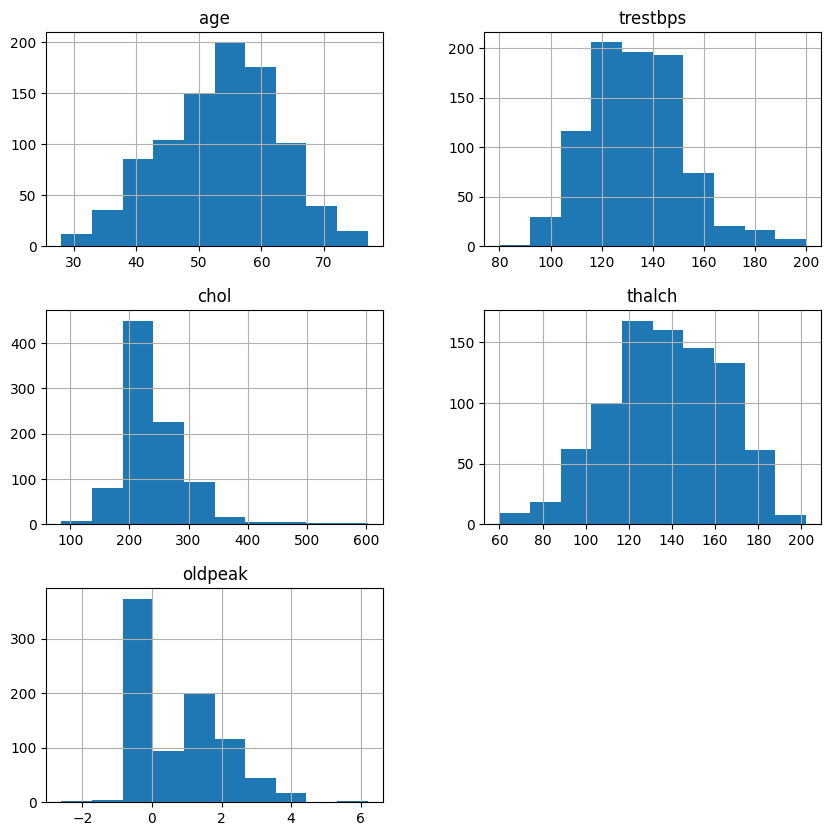

In [427]:
cardio_df.select_dtypes(include=[np.number]).hist(figsize=(10,10))

In [428]:
cardio_df.select_dtypes(include=[object,CategoricalDtype]).describe()

,sex,origin,cp,fbs,restecg,exang,slope,ca,thal,num
count,918,918,918,829,918,863,610,309.0,434,918
unique,2,4,4,2,3,2,3,4.0,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,0.0,normal,0
freq,724,304,495,691,551,526,345,181.0,196,411


In [429]:
cardio_df.select_dtypes(include=[object,CategoricalDtype]).value_counts()

sex     origin         cp               fbs    restecg         exang  slope      ca   thal               num
Male    Cleveland      atypical angina  False  normal          False  upsloping  0.0  normal             0      9
                       non-anginal      False  normal          False  upsloping  0.0  normal             0      7
Female  Cleveland      non-anginal      False  normal          False  flat       0.0  normal             0      6
                                               lv hypertrophy  False  upsloping  0.0  normal             0      5
                       atypical angina  False  normal          False  upsloping  0.0  normal             0      5
                                                                                                               ..
Male    Cleveland      typical angina   True   lv hypertrophy  False  flat       1.0  normal             0      1
                                                                                                         1      1
                                               normal          False  flat       0.0  reversable defect  0      1
        Hungary        asymptomatic     False  normal          True   flat       0.0  reversable defect  1      1
        VA Long Beach  asymptomatic     False  normal          True   flat       0.0  reversable defect  1      1
Name: count, Length: 220, dtype: int64

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

---

 ##Variabled del estado del corazon
 - Son variables que ocuparian de la medicion de la salud cardiaca del paciente, por lo cual cuando no se captura uno es normal que no se caputren los demas, por lo cual son MNCR


 Presión arterial en reposo (en mm Hg al ingreso al hospital)

 thalach: Frecuencia cardíaca máxima alcanzada

 exang: Angina inducida por ejercicio (Verdadero / Falso)

 oldpeak: Depresión del segmento ST inducida por ejercicio respecto al reposo

---
## Azucar en la sangre
- No se nota una relacion con alguna otra variable que podria estar relacionada por lo tanto se incluna mas hacia MCAR


fbs: Si el azúcar en ayunas > 120 mg/dl

---
##Nivel de colesterol en la sangre
- No se nota una relacion con alguna otra variable que podria estar relacionada por lo tanto se incluna mas hacia MCAR

chol: Colesterol sérico en mg/dl



In [430]:
drop = cardio_df.isna().sum()/cardio_df.shape[0] > 0.30

for column,value in drop.items():
  if value:
    cardio_df.drop(column,axis=1,inplace=True)
    print(f"droped column: {column}")

droped column: slope
droped column: ca
droped column: thal


<Axes: ylabel='id'>

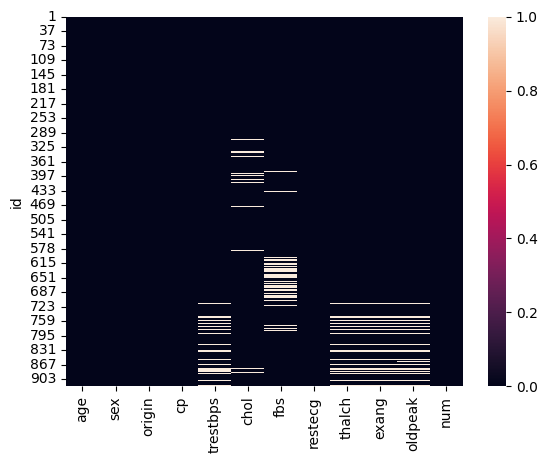

In [431]:
sns.heatmap(cardio_df.isna())

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

---

 - Las personas sin registro de thalch son mas propensas a ser mayores que las que si lo reportan. En el histograma las personas que no tienen los datos registrados estan mas sesgados hacia la izquierda. El valor p de la prueba t es lo suficientemente pequeño para implicar que existe una diferencia significativa entre las muestras. Lo cual implica que la variable es MNAR

 - El colesterol de las personas sin valores de thalch tienen mas valores extremos, pero no se observa una diferencia significativa en el rango intercuartilico. En su histograma tambien se puede ver que el que la muestra sin medida thalch tiene mayor variacion. El valor p de la prueba t indica que no existe diferencia significativa entre las dos muestras, lo cual apunta a MCAR

 - El histograma para restecg muestra que los datos podrian ser MNAR ya que existe una diferencia significativa en la distribucion de frecuencias, especialmente en la categoria: st-t abnormality, indicando que si se tiene el dato del paciente es mas probable que haya entrado ya con una complicación. Sin embargo la prueba de hipotesis contracice que sea MNAR que que no encuentra una relacion significativa entre las variables, indicando MCAR

 - El histograma de cp muestra que hay mayores frecuencias para non anginal, por lo cual significa que es probable que los asintomaticos son menos prompensos a realizarse las pruebas que capturan el thalch. Implicando que sean MNAR, esto tambien es confirmado con el valor alto del pvalue de 0.15, lo cual puede implicar MAR o MNAR

In [432]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [433]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

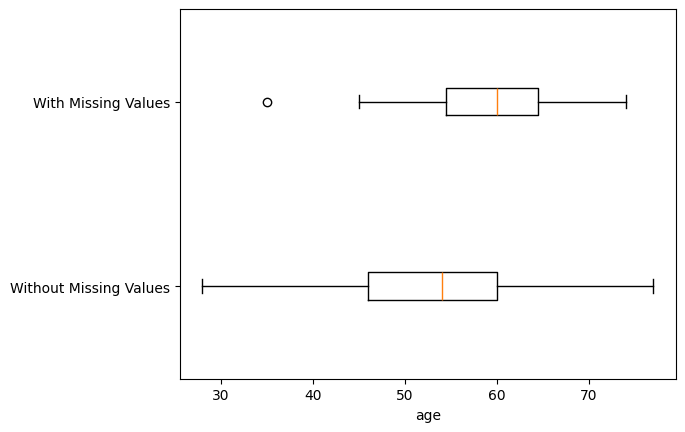

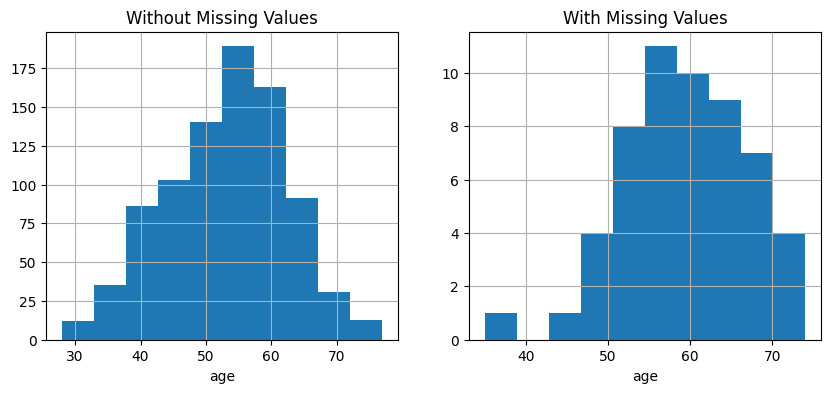

p-value of t-test: 1.5041244185890902e-06


In [434]:
Diagnose_MV_Numerical(cardio_df,'age',BM_MV)

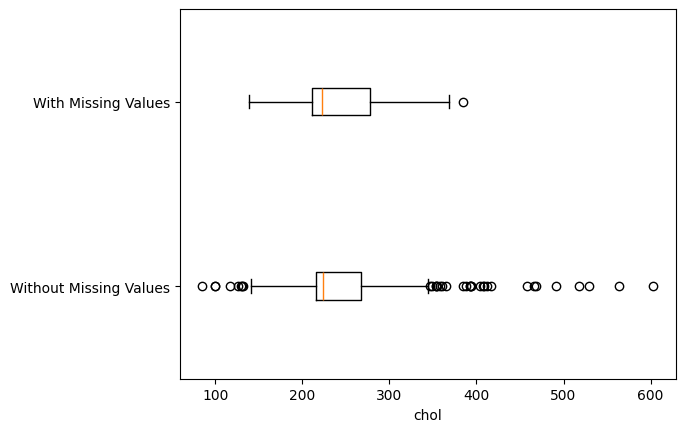

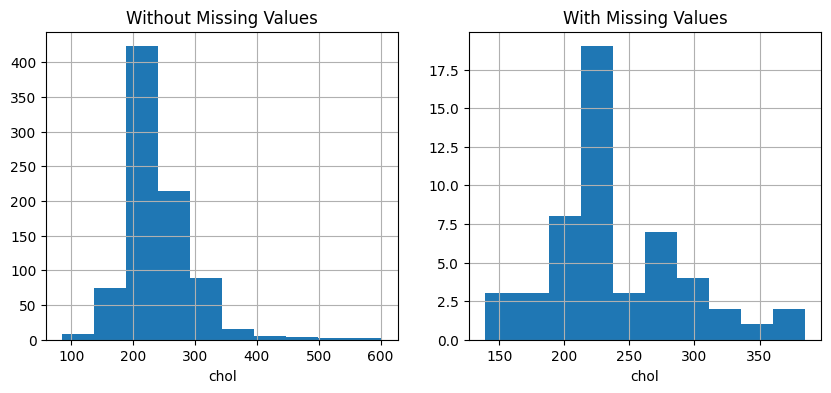

p-value of t-test: 0.7165289974295672


In [435]:
Diagnose_MV_Numerical(cardio_df,'chol',BM_MV)

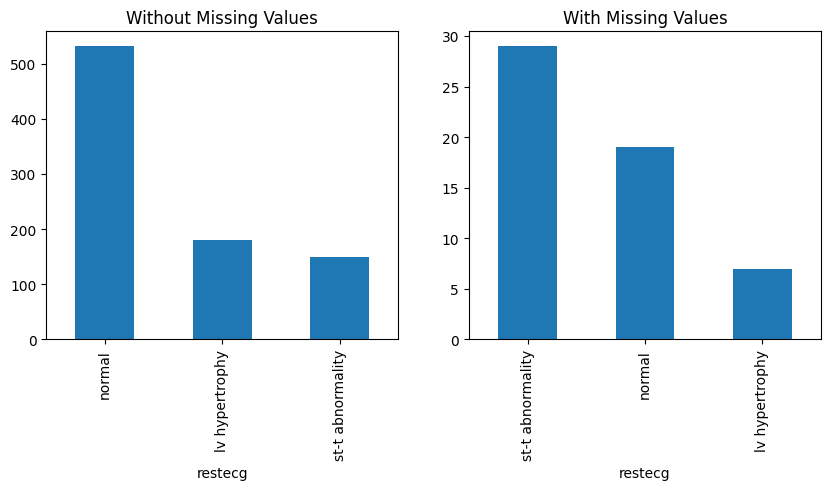

p-value of Chi_squared test: 1.1472889573985467e-09


In [436]:
Diagnose_MV_Categorical(cardio_df,'restecg',BM_MV)

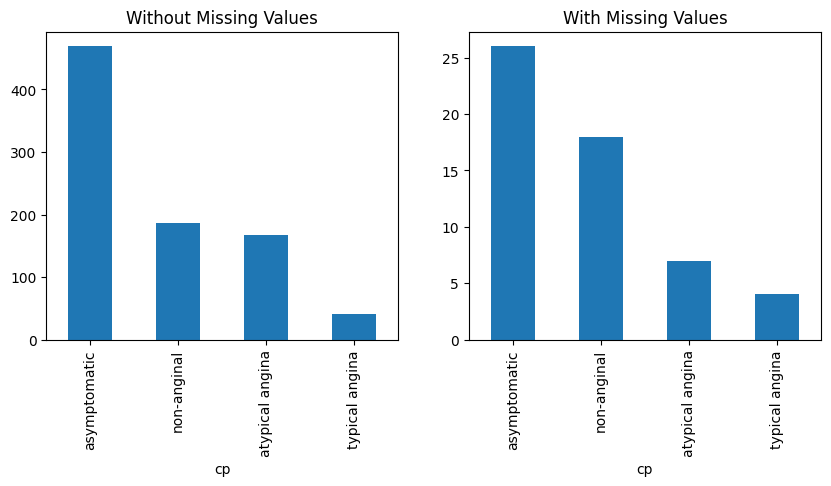

p-value of Chi_squared test: 0.15420097177251701


In [437]:
Diagnose_MV_Categorical(cardio_df,'cp',BM_MV)

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [438]:
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       918 non-null    int64   
 1   sex       918 non-null    object  
 2   origin    918 non-null    object  
 3   cp        918 non-null    object  
 4   trestbps  859 non-null    float64 
 5   chol      888 non-null    float64 
 6   fbs       829 non-null    object  
 7   restecg   918 non-null    object  
 8   thalch    863 non-null    float64 
 9   exang     863 non-null    object  
 10  oldpeak   856 non-null    float64 
 11  num       918 non-null    category
dtypes: category(1), float64(4), int64(1), object(6)
memory usage: 87.2+ KB


In [439]:
cardio_df.exang.unique()

array([False, True, nan], dtype=object)

/tmp/ipykernel_556/1551621141.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(True if np.random.rand() > ratio else False))


<Axes: ylabel='id'>

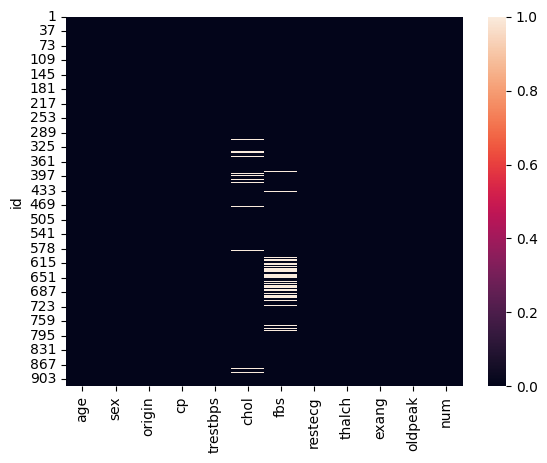

In [440]:
cardio_df['thalch'] = cardio_df.groupby('restecg')['thalch'].transform(lambda x: x.fillna(x.median()))

# Calculamos el ratio de manera similar a tu lógica original pero evitando errores de indexación con nulos
num_true = cardio_df.exang[cardio_df.exang == True].shape[0]
n = cardio_df.shape[0]
ratio = num_true / n

cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(True if np.random.rand() > ratio else False))
cardio_df['oldpeak'] = cardio_df.groupby('restecg')['oldpeak'].transform(lambda x: x.fillna(x.median()))
cardio_df['trestbps'] = cardio_df.groupby('restecg')['trestbps'].transform(lambda x: x.fillna(x.median()))

sns.heatmap(cardio_df.isna())

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.
---
Para chol usare la media ya que el valor fue MCAR debido a la prueba de hipotesis y por lo tanto la media no afecta a la distribucion

Para fbs se uso el valor mas frequente ya que la distribucion estaba fuertemente sesgada


In [441]:
cardio_df.chol.unique()

array([233., 286., 229., 250., 204., 236., 268., 354., 254., 203., 192.,
       294., 256., 263., 199., 168., 239., 275., 266., 211., 283., 284.,
       224., 206., 219., 340., 226., 247., 167., 230., 335., 234., 177.,
       276., 353., 243., 225., 302., 212., 330., 175., 417., 197., 198.,
       290., 253., 172., 273., 213., 305., 216., 304., 188., 282., 185.,
       232., 326., 231., 269., 267., 248., 360., 258., 308., 245., 270.,
       208., 264., 321., 274., 325., 235., 257., 164., 141., 252., 255.,
       201., 222., 260., 182., 303., 265., 309., 307., 249., 186., 341.,
       183., 407., 217., 288., 220., 209., 227., 261., 174., 281., 221.,
       205., 240., 289., 318., 298., 564., 246., 322., 299., 300., 293.,
       277., 214., 207., 223., 160., 394., 184., 315., 409., 244., 195.,
       196., 126., 313., 259., 200., 262., 215., 228., 193., 271., 210.,
       327., 149., 295., 306., 178., 237., 218., 242., 319., 166., 180.,
       311., 278., 342., 169., 187., 157., 176., 24

<Axes: >

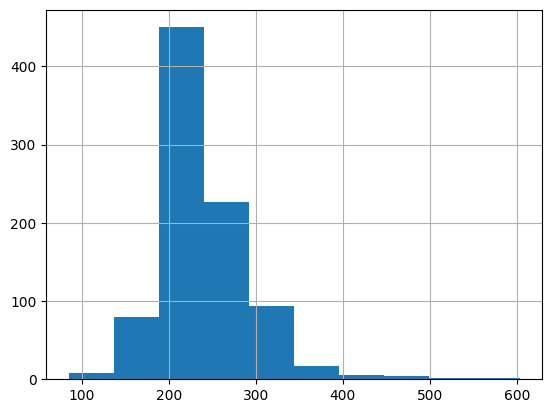

In [442]:
cardio_df.chol.hist()

In [443]:
cardio_df.fbs.unique()

array([True, False, nan], dtype=object)

<Axes: >

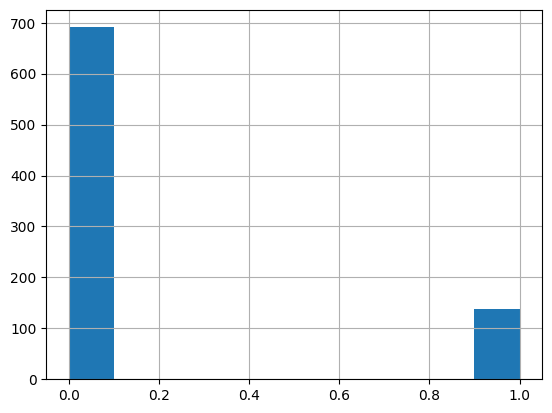

In [444]:
# Convertimos los booleanos a enteros (0 y 1) o texto para poder graficar el histograma sin errores
cardio_df.fbs.dropna().astype(int).hist()

<Axes: >

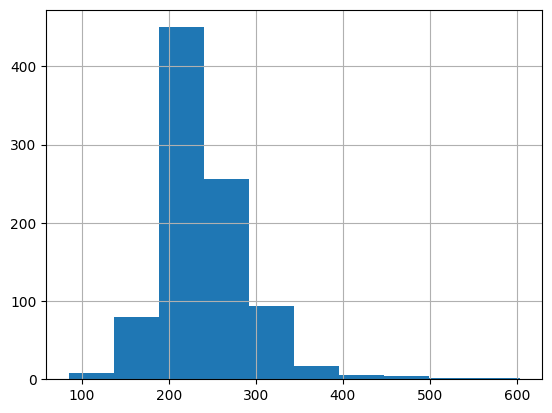

In [445]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean')
cardio_df.chol = imputer.fit_transform(cardio_df[['chol']])
cardio_df.chol.hist()


<Axes: >

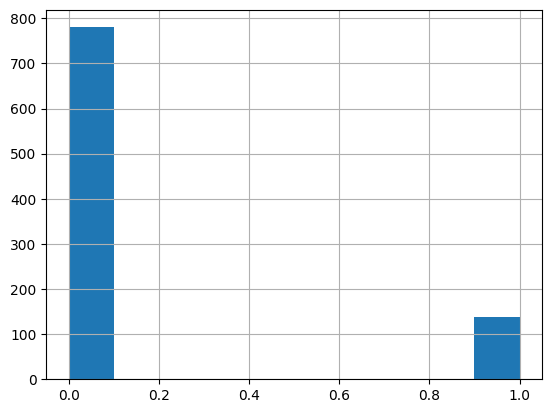

In [446]:
imputer = SimpleImputer(strategy='most_frequent')
# Usamos .ravel() para convertir el arreglo de 2D de vuelta a 1D y asignamos con corchetes de forma segura
cardio_df['fbs'] = imputer.fit_transform(cardio_df[['fbs']]).ravel()

# Convertimos a entero para poder graficar el histograma sin errores de tipos booleanos
cardio_df.fbs.astype(int).hist()

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

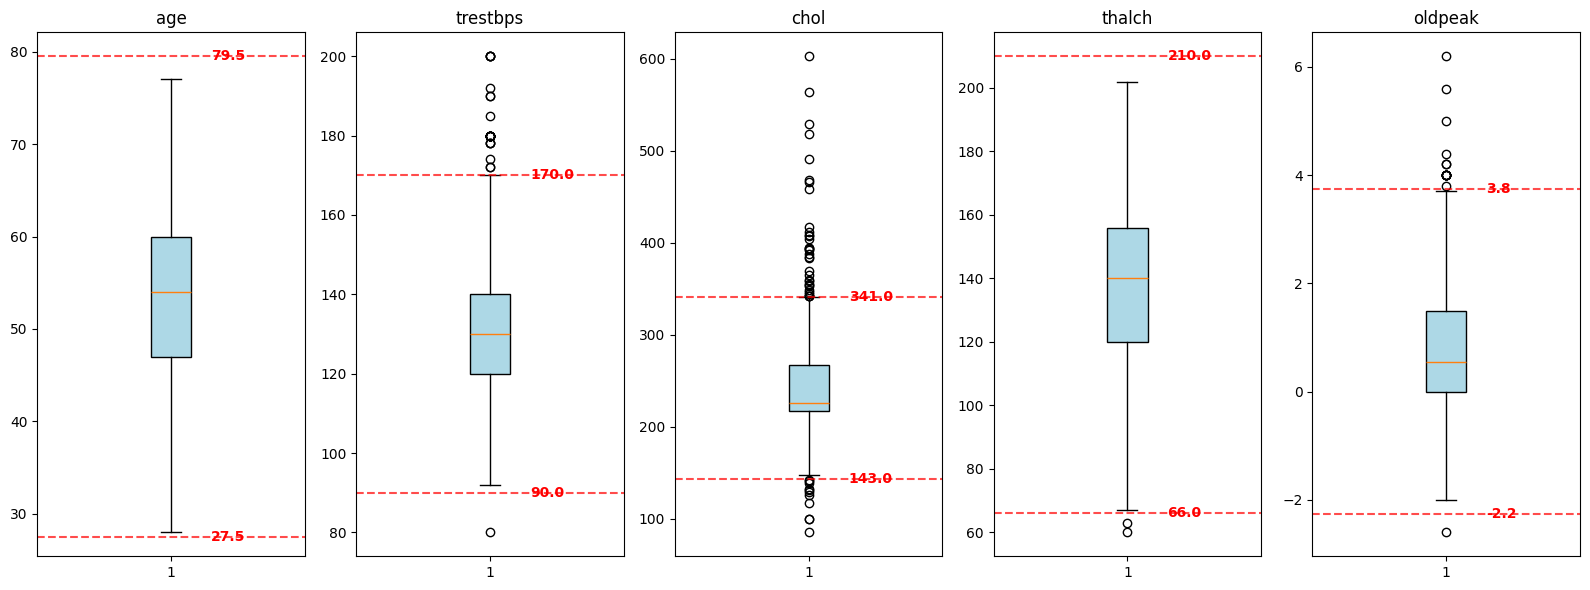

In [447]:
import numpy as np
import matplotlib.pyplot as plt

numericas = cardio_df.select_dtypes(include=[np.number])

# Configuramos una cuadrícula de gráficos para mostrar cada variable numérica de forma clara
fig, axes = plt.subplots(nrows=1, ncols=len(numericas.columns), figsize=(16, 6), sharey=False)

for i, col in enumerate(numericas.columns):
    ax = axes[i]
    # Graficamos el boxplot individual en su respectivo eje
    ax.boxplot(numericas[col], patch_artist=True, boxprops=dict(facecolor='lightblue'))
    ax.set_title(col)

    # Calculamos IQR y límites para los valores atípicos
    q1 = numericas[col].quantile(0.25)
    q3 = numericas[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    # Dibujamos las líneas de corte para los valores atípicos en el gráfico
    ax.axhline(upper_limit, color='red', linestyle='--', alpha=0.7, label=f'Sup: {upper_limit:.1f}')
    ax.axhline(lower_limit, color='red', linestyle='--', alpha=0.7, label=f'Inf: {lower_limit:.1f}')

    # Añadimos las etiquetas de texto de los límites numéricos en los ejes correspondientes
    ax.text(1.15, upper_limit, f'{upper_limit:.1f}', color='red', fontweight='bold', va='center')
    ax.text(1.15, lower_limit, f'{lower_limit:.1f}', color='red', fontweight='bold', va='center')

plt.tight_layout()
plt.show()

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.
---

Si coinciden ya que son valores menores a 90 y mayores de 170

In [448]:
# Definición de cuartiles y rango intercuartílico (IQR)
q1 = cardio_df.trestbps.quantile(0.25)
q3 = cardio_df.trestbps.quantile(0.75)
iqr = q3 - q1

# Definición de límites para detección de outliers
limite_superior = q3 + 1.5 * iqr
limite_inferior = q1 - 1.5 * iqr

# Filtrado correcto de registros utilizando operadores vectoriales (& / |) y paréntesis
atypical = cardio_df.trestbps[(cardio_df.trestbps > limite_superior) | (cardio_df.trestbps < limite_inferior)]
atypical.unique()

array([172., 180., 200., 174., 178., 192., 190.,  80., 185.])

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

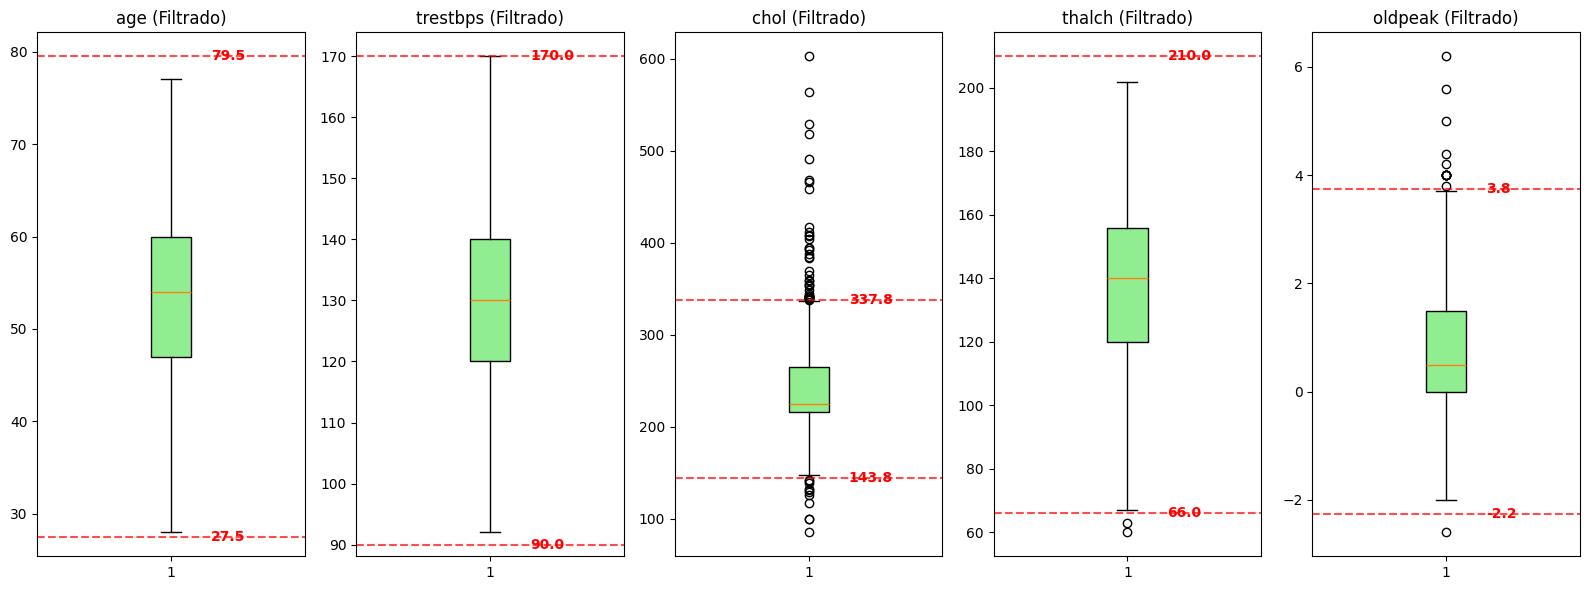

In [449]:
# 10. Eliminamos los valores atípicos de la variable trestbps
# Nos quedamos con los registros dentro del rango [limite_inferior, limite_superior]
filtered_df = cardio_df[(cardio_df.trestbps >= limite_inferior) & (cardio_df.trestbps <= limite_superior)]

# Seleccionamos las variables numéricas del conjunto filtrado
numericas_filtradas = filtered_df.select_dtypes(include=[np.number])

# Replicamos la configuración de cuadrícula de gráficos para las variables filtradas
fig, axes = plt.subplots(nrows=1, ncols=len(numericas_filtradas.columns), figsize=(16, 6), sharey=False)

for i, col in enumerate(numericas_filtradas.columns):
    ax = axes[i]
    # Graficamos el boxplot individual
    ax.boxplot(numericas_filtradas[col], patch_artist=True, boxprops=dict(facecolor='lightgreen'))
    ax.set_title(f"{col} (Filtrado)")

    # Calculamos IQR y límites para la visualización de referencia
    q1 = numericas_filtradas[col].quantile(0.25)
    q3 = numericas_filtradas[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    # Dibujamos las líneas de corte de referencia
    ax.axhline(upper_limit, color='red', linestyle='--', alpha=0.7)
    ax.axhline(lower_limit, color='red', linestyle='--', alpha=0.7)

    # Añadimos las etiquetas de texto con los valores de los límites
    ax.text(1.15, upper_limit, f'{upper_limit:.1f}', color='red', fontweight='bold', va='center')
    ax.text(1.15, lower_limit, f'{lower_limit:.1f}', color='red', fontweight='bold', va='center')

plt.tight_layout()
plt.show()

---

**Declaración de uso de IA**

* Google. (2026). *Gemini (basado en Flash 3.5)* [Modelo de lenguaje grande], utilizado para genreación de código y depuración. https://colab.reasearch.google.com

---